# <span style="color:red">**Question Answering - Part 2**</span>

Now that you have your tokenized dataset from the first part, you will use it to define the **labels** of each example. These labels will be used (between other things) for the **training** of the distilBERT model. Finally, you will **use** your model to get the answers for a few example questions and to **evaluate** this model on a larger validation set.



## <span style="color:#ff5500">Hardware and software requirements</span >

Before diving into the code of this second part, you need to setup the GPU as well as downloading the required libraries.

This project can either be done on your computer or on Google Colab, but for the models to be trained in reasonable amount of time, it **requires** a GPU. This GPU is necessary for this **second part** of the project.

### <span style="color:#ff8800">A. Recommended choice: using Colab</span >

Using Google Colab to complete the assignment is your best bet for a hassle
free experience on this project.


#### <span style="color:#ffcc00">Instructions to access Colab GPUs</span >
As you may already know (if not, you will soon !), training neural networks is a computationally very expensive task. This is why using specific hardware is highly beneficial (but it is sometimes tricky to get properly configured).  With that respect, Colab provides you with free to use preconfigured hardware you can use to train your models.

In particular, it gives you an opportunity to train your model using either:

- a CPU (aka Cental Processing Unit; this is your slowest option)
- a GPU (aka Graphical Processing Unit; which is much faster !!)
- a TPU (aka Tensor Processing Unit; even faster, but chances are you won't get access to them since they are allocated to paid customers first. In addition, they are not compatible with a specific library we use.)

By default, your Colab Notebook is running on a session whose python interpreter only uses a CPU (no GPU/TPU available). To change that and use a GPU enabled session, you should click on the resources usage summary (top right of this window). To be complete, you should click first on "Connect" to see the ressources.

**Notice that you could sometimes not have access to the GPUs on Colab, don't panic, just wait some hours until it is available.** The best way to prevent this situation is to only use the GPU when you are ready to train and evaluate your model.


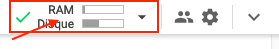


This will open a panel on the left of your browser where you can chose to "Modify execution type". And then select the kind of hardware acceleration you want to use. Select GPU to be able to execute the project.

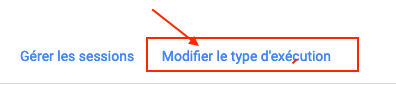

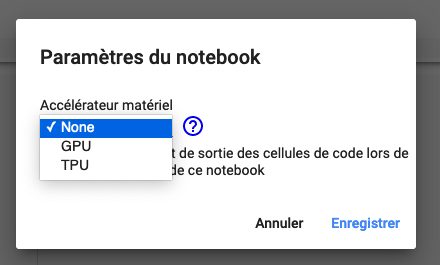

If you want to use Colab, you will need to mount it to access the files on your cloud:

**Note**: you will need to grant it all the permissions. You will also receive a warning on your email about a connection from another device. This is normal and expected.

In [ ]:
# Execute this to be able to access the drive
from google.colab import drive
drive.mount('/content/drive')

### <span style="color:#ff8800">B. Other choice: Locally on your machine</span>

Should you decide to install the software on your own machine; then the
**very first step** of this project would consist in installing [PyTorch][2]
on your machine. You can use the generated command (while clicking on PyTorch link) but first read the next lines.

Please note that if you don't have a GPU with at least 4GB of RAM, you should not try to train models you will built in this projet locally. Also note that depending on the type of GPU (NVIDIA vs AMD), your installation of PyTorch will differ a bit so be cautious about the compute platform you have. Finally, note that the torchaudio and torchvision libraries are not required for this project.

### <span style="color:#ff8800">C. Libraries</span>

Several other libraries are required for this project:
* [transformers][3]
* [datasets][4]
* [evaluate][5]
* [accelerate][6]

##### <span style="color:#ffcc00">Installation of libraries in Colab </span>

To install all those libraries on Colab direclty, you can use this snippet in a python cell of your notebook:

(You will get an error about a dependency, it is normal. The last line of the install should start with "Successfully installed ...")

[2]:<https://pytorch.org/get-started/locally/>
[3]:<https://huggingface.co/docs/transformers/index>
[4]:<https://huggingface.co/docs/datasets/index>
[5]:<https://huggingface.co/docs/evaluate/index>
[6]:<https://huggingface.co/docs/accelerate/index>

In [ ]:
# Execute this to be able to install the required libraries for this part of the project
!pip install fsspec==2024.10.0
!pip install numpy torch transformers datasets evaluate accelerate

## <span style="color:#ff5500">Loading elements from first part</span>

To be able to start this part of the project, you should first load the datasets you have saved previously:

In [ ]:
from datasets import load_from_disk
from transformers import AutoTokenizer

tokenized_train = load_from_disk("/content/drive/MyDrive/CL/tokenized_train_dataset/tokenized_train_dataset")          # Change this path with where you stored your tokenized train dataset
tokenized_validation = load_from_disk("/content/drive/MyDrive/CL/tokenized_validation_dataset/tokenized_validation_dataset")   # Change this path with where you stored your tokenized validation dataset

model_checkpoint = "distilbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

## <span style="color:#ff5500">**Section three**: data labeling</span>

Now that we have the tokenized version of both datasets, we have to define the **labels**. These labels will be used during the training of the model to indicate where the actual answer lies in the tokenized context and, during the evaluation, to assess the quality of the predictions of a model. Due to the tokenization, the **expected answers**, annotated in the original dataset within the *context* (= a text) of each question, must be mapped to specific positions of the tokens representing this context. This is the objective of the **labeling** step.

For each segment of a given example in the dataset, a label is a tuple (**start_position**, **end_position**) where:

- the **start_position** is the index of the first token of the answer
- the **end_position** is the index of the last token of the answer (that is still part of the answer).

If the answer is not (or partially not) included in the (possibly, truncated) context of the segment, the label should be (**0**, **0**) to indicate that the answer is not present.

---
> **EXAMPLE**


Consider the following example (index 12150 in the tokenized train dataset):

- question: "*Which year did the USSR cancel the N1 rocket program after two failures that didn't launch?*"
- context: "*Meanwhile, the USSR continued briefly trying to perfect their N1 rocket, finally canceling it in 1976, after two more launch failures in 1971 and 1972.*"
- answers: {"text": "*1976*", "answer_start": 97}
- tokenized question+context (as sub-word tokens for readability):

[ '[CLS]', 'Which', 'year', 'did', 'the', 'USSR', 'cancel', 'the', 'N', '##1', 'rocket', 'program', 'after', 'two', 'failures', 'that', 'didn', "'", 't', 'launch', '?', '[SEP]', 'Meanwhile', ',', 'the', 'USSR', 'continued', 'briefly', 'trying', 'to', 'perfect', 'their', 'N', '##1', 'rocket', ',', 'finally', 'cancel', '##ing', 'it', 'in', '1976', ',', 'after', 'two', 'more', 'launch', 'failures', 'in', '1971', 'and', '1972', '.', '[SEP]', '[PAD]', '[PAD]', ..., '[PAD]']

Here, the answer (1976) is fully inside the segment context. The corresponding label is (41, 41). Notice that the "answer_start" (97 here) refers to the index of the first character within the string forming the answer ("1" for "1976") while the first label (41) refers to the first index of the token of the answer in the question+context segment.


---
> **IMPORTANT REMARKS**

- If the answer is composed of only 1 token, start_position == end_position
- There may be more than one answer for some examples. You should consider only the **first** answer, for this labeling.
- The 'offset_mapping' key of the tokenized dataset is very useful!



### <span style="color:#ff8800">Question 1: Function for labeling</span>

Provide here a function named **labeling** that takes as argument **tokenized_dataset**, a *Dataset* type from huggingface, and **tokenizer_sep_id**, the id of the [SEP] token provided by the model tokenizer. The function must return the labeled dataset.

As output, in addition to the existing keys (= columns) of the **tokenized_dataset**, the **labeled_dataset** should contain two new keys:

* 'start_positions': the token indices where the answer starts in each (truncated) question+context
* 'end_positions': the token indices where the answer ends in each (truncated) question+context
* 'context_start': the token indices where the context starts (i.e. right after the first occurrence of [SEP]) in a question+context

Recall that **each row** of a tokenized dataset represents **one example** (a question+context) which has one or more segment(s): question+(truncated) context pair(s).

> **QUESTION**
>
> Complete the given template for the **labeling** function by following the indications given by the TODO's.

This function uses a sub-function to define the label of a given example. Then, using the map(), the sub-function is applied to the whole dataset.

**NOTES**:
- To determine if the full answer is in the context, you first need to determine where the context starts and ends. You can do that by detecting the indexes of the first and last [SEP] inside the ids of the question+context.
- There is **one** 'start_position' and one 'end_position' for **each** question+context **segment** (recall that due to truncation, there can be several segments). In contrast, there is **one** 'context_start' for each **example**, because the question is not truncated (only the context could be). Therefore the 'context_start' is the same for all question+context segments associated to the same example. Therefore, this 'context_start' needs to be stored only **once** for each example.  

In [ ]:
def labeling(tokenized_dataset, tokenizer_sep_id):

    def label(example):

        answers = example["answers"]
        input_ids = example["input_ids"]
        offset_mapping = example["offset_mapping"]

        if answers["answer_start"]:
            start_char = answers["answer_start"][0]
            end_char = start_char + len(answers["text"][0])
        else:
            return {
                'start_positions': [0] * len(offset_mapping),
                'end_positions': [0] * len(offset_mapping),
                'context_start': 0
            }

        start_positions = []
        end_positions = []

        context_start = None
        for segment in offset_mapping:
            sep_positions = [i for i, token in enumerate(segment) if input_ids[offset_mapping.index(segment)][i] == tokenizer_sep_id]
            if len(sep_positions) >= 2:
                context_start = sep_positions[0] + 1
                context_end = sep_positions[1] - 1

            if context_start is None:
                continue

            start_pos = 0
            end_pos = 0

            for idx, (start, end) in enumerate(segment):
                if start <= start_char < end:
                    start_pos = idx
                if start < end_char <= end:
                    end_pos = idx

            if start_pos < context_start or start_pos > context_end:
                start_pos = 0
                end_pos = 0

            start_positions.append(start_pos)
            end_positions.append(end_pos)

        return {
            'start_positions': start_positions,
            'end_positions': end_positions,
            'context_start': context_start
        }

    labeled_dataset = tokenized_dataset.map(label)
    return labeled_dataset


In [ ]:
labeled_train = labeling(tokenized_train,tokenizer.sep_token_id)
labeled_validation = labeling(tokenized_validation,tokenizer.sep_token_id)

In [ ]:
labeled_validation = ...

In [ ]:
# save labeled train and labeled validation datasets on disk (to be able to restart from there directly)

labeled_train.save_to_disk("/content/drive/MyDrive/CL/labeled_train2")
labeled_validation.save_to_disk("/content/drive/MyDrive/CL/labeled_validation2")

### <span style="color:#ff8800">Question 2: Labels (1)</span>

To test the labelization of the training data, we will ask you to generate several labels in the following questions.

> **QUESTION**
>
> What is the labeling output for the example at index 1234 in the train dataset?

Your answer must be a tuple of two lists, and an integer. The first list correponds to the *start_positions* and the second to the *end_positions*. Each element of the lists corresponds to a segment of this example.
Thus, each list has a length equal to the number of segments of this example. The 3rd element of the tuple is the *context_start* of this example.


In [ ]:
labeled_train = load_from_disk("/content/drive/MyDrive/CL/labeled_train2")          # Change this path with where you stored your tokenized train dataset
labeled_validation = load_from_disk("/content/drive/MyDrive/CL/labeled_validation2")   # Change this path with where you stored your tokenized validation dataset


# print(tokenizer.convert_ids_to_tokens(ids_context))
print(labeled_train[12150])
 #([0], [0], 0)

In [ ]:
ids_context = labeled_train[1234]["input_ids"][0][23:26]
print(ids_context)
print(tokenizer.convert_ids_to_tokens(ids_context))
print(labeled_train[1234])

### <span style="color:#ff8800">Question 3: Labels (2)</span>

> **QUESTION**
>
> What is the labeling output for the example at index 2439 in the train dataset?

Your answer must be a tuple of two lists, and an integer. The first list correponds to the *start_positions* and the second to the *end_positions*. Each element of the lists corresponds to a segment of this example.
Thus, each list has a length equal to the number of segments of this example. The 3rd element of the tuple is the *context_start* of this example.


In [ ]:
ids_context = labeled_train[2439]["input_ids"][0][14:16]
print(ids_context)
print(tokenizer.convert_ids_to_tokens(ids_context))
print(labeled_train[2439])
 #([0], [0], 0)

### <span style="color:#ff8800">Question 4: Labels (3)</span>

> **QUESTION**
>
> What is the labeling output for the example at index 59807 in the train dataset?

Your answer must be a tuple of two lists, and an integer. The first list correponds to the *start_positions* and the second to the *end_positions*. Each element of the lists corresponds to a segment of this example.
Thus, each list has a length equal to the number of segments of this example. The 3rd element of the tuple is the *context_start* of this example.




In [ ]:

ids_context = labeled_train[59807]["input_ids"][0][160:164]
print(ids_context)
print(tokenizer.convert_ids_to_tokens(ids_context))
print(labeled_train[59807])

## <span style="color:#ff5500">**Section Four**: Training loop and inference</span>

In this section, your task is to complete the templates of the functions used to train the model.

The training data will be divided into batches. Each batch contains a certain number of examples and batches are passed one by one to the model during the training. The model parameters are updated after processing each batch of examples.


**Note**:
- the "..." below may have to be replaced by more than one line!
- we use the [accelerate][1] library to load the model and the data on a GPU. Do not hesitate to read about it (by following the hyperlink).


[1]: <https://huggingface.co/docs/accelerate/index>

In [ ]:
### Imports

import torch
from torch.utils.data import DataLoader
from transformers import get_scheduler, AutoModelForQuestionAnswering
from torch.optim import AdamW
from accelerate import Accelerator
from datasets import load_from_disk

###  <span style="color:#ff8800">**Subsection One**: Train function </span>


Before diving into the train function itself, we need a function that, for each example in a batch, retrieves the *input_ids*, *attention_mask*, *start_positions*, and *end_positions* of the (truncated) segment(s) for this example and put each of them in a flat list containing these informations for all segments of all examples within this batch. Each of these flat lists is then turned into a tensor.

In [ ]:
def collate_train_fn(batch):

    # batch: a batch of example from a labeled dataset
    all_input_ids = []
    all_attention_mask = []
    all_start_positions = []
    all_end_positions = []

    # Iterate through each example in the batch
    for example in batch:
        # Retrieve the input_ids, attention_mask, start_positions, and end_positions from the example
        input_ids = example['input_ids']
        attention_mask = example['attention_mask']
        start_positions = example['start_positions']
        end_positions = example['end_positions']

        # Flatten the data (if needed) and append it to the respective lists
        all_input_ids.extend(input_ids)
        all_attention_mask.extend(attention_mask)
        all_start_positions.extend(start_positions)
        all_end_positions.extend(end_positions)

    return {
        'input_ids' : torch.tensor(all_input_ids),
        'attention_mask' : torch.tensor(all_attention_mask),
        'start_positions' : torch.tensor(all_start_positions),
        'end_positions' : torch.tensor(all_end_positions),
    }

The training loop follows this general guideline:

1. You get the outputs of the model after passing it the inputs from each segment. This is known as the forward pass and one of the outputs is the loss.
2. Using this loss, a back-propagation is performed to compute the gradient of the loss.
3. From this gradient, an update of the model parameters (i.e. the weights and biases) is performed.
4. Next, the learning rate (i.e. the step size in direction of the gradient) is updated
5. Finally, the gradients are reset to prevent an accumulation.



Complete the given template below for the train function with the following indications:

- Train the model for 3 epochs
- The batch size for the DataLoader should be 8
- The training dataset should be shuffled
- The initial learning rate of the optimizer should be $2 \times 10^{-5}$
- The scheduler should be linear
- The scheduler should have 0 warmup steps
- The number of training steps of the scheduler should be (number of training epochs) $\times$ (number of training batches)

See the different documentations to use the correct hyperparameters and set their respective values.



**Friendly advice**: you should save your model at each epoch to save time for the following questions! It is also **highly recommended** to test your implementation of the train function on a small fraction of the training set (e.g. 100 examples) and to monitor the loss computed.


In [ ]:
### Training function

def train(model, labeled_dataset, n_epochs):
    # model: a HuggingFace model
    # labeled_dataset: a labeled dataset obtained from your labeling function above
    # n_epochs: the number of training epochs


    # TODO: complete to meet conditions
    train_dataloader = DataLoader(
        labeled_dataset,
        collate_fn=collate_train_fn,
        batch_size=8,
        shuffle=True
    )

    optimizer = AdamW(model.parameters(), lr=2e-5)

    #############################################
    #############accelerate part#################
    accelerator = Accelerator(mixed_precision='fp16')
    model, optimizer, train_dataloader= accelerator.prepare(
            model, optimizer, train_dataloader
            )
    ##########end of accelerate part#############
    #############################################

    ### Scheduler

    # TODO: complete to meet conditions
    lr_scheduler = get_scheduler(
        name="linear",
        optimizer=optimizer,
        num_warmup_steps=0,
        num_training_steps=n_epochs * len(train_dataloader),
    )

    # (Optional, if you want a progress bar)
    # from tqdm.auto import tqdm
    # progress_bar = tqdm(range(num_training_steps))

    ### Training
    for epoch in range(n_epochs):


        # This instruction sets the model to training mode (as opposed to evaluation mode)
        model.train()

        for step, batch in enumerate(train_dataloader):

            # Get ouputs and loss from the model
            outputs = model(**batch)
            loss = outputs.loss

            # Backpropagation
            #############################################
            #############accelerate part#################
            accelerator.backward(loss)
            #############end of accelerate part##########
            #############################################

            # TODO: Update model parameters (i.e. weights and biases of the model) by performing an optimization step
            # Hint: look at optimizer
            optimizer.step()
            # TODO: Update learning rate
            # Hint: look at lr_scheduler
            lr_scheduler.step()

            # TODO: Zero gradients to prevent gradient accumulation
            optimizer.zero_grad()


            # (Optional, if you want a progress bar)
            #progress_bar.update(1)

        # TODO: Save your model at each epoch (do not forget to put the epoch in the name of the file to have one file per epoch)
        output_dir = f"/content/drive/MyDrive/CL/epochsh/model_epoch_{epoch+1}"
        accelerator.wait_for_everyone()
        unwrapped_model = accelerator.unwrap_model(model)
        unwrapped_model.save_pretrained(output_dir, save_function=accelerator.save)


In [ ]:
# TODO: Apply the function train to the model

### Load model

model_checkpoint = "distilbert-base-cased"
model = AutoModelForQuestionAnswering.from_pretrained(model_checkpoint)

# Reload labeled train dataset from disk (if needed)
labeled_train = load_from_disk("/content/drive/MyDrive/CL/labeled_train2")
small_train_dataset = labeled_train.select(range(100))

### Train the model
train(model,labeled_train,3)
print(sum(p.numel() for p in model.parameters()))

### <span style="color:#ff8800">Question 1: Number of parameters</span>

You just trained your model on the labeled dataset and it took a certain amount of time... The amount of parameters plays an important role regarding this training time.

> **QUESTION**
>
> What is the total number of parameters (trainable and non-trainable) in the model?

Report your answer as a Python dictionary where the key is "n_parameters" and its value is your answer as an integer.

In [ ]:
{"n_parameters": 65192450} 

###  <span style="color:#ff8800">**Subsection Two**: Inference function </span>

Before looking at the predictions of the model, we need to prepare the data to give them to the DataLoader inside the inference function.

Complete the collate function for the evaluation given the template below. As before, each element must be a flatten list.
Be careful, each list must have the same length as the others, which corresponds to the total number of segments in the batch. So, if some information (e.g. 'context_start') is stored once for each example, it must be repeated as many times as the number of segments of this example.  








In [ ]:
def collate_eval_fn(batch):
    # format the model inputs as already done for the training
    model_inputs = collate_train_fn(batch)

    all_contexts = []
    all_context_starts = []
    all_ids = []
    all_offset_mappings = []

    # Iterate through each example in the batch
    for example in batch:
        # Retrieve the context and other information for inference
        context = example['context']
        context_start = example['context_start']
        example_id = example['id']
        offset_mapping = example['offset_mapping']

        num_segments = len(example['input_ids'])

        all_contexts.extend([context] * num_segments)
        all_context_starts.extend([context_start] * num_segments)
        all_ids.extend([example_id] * num_segments)
        all_offset_mappings.extend(offset_mapping)

    eval_inputs = {
          'context' : all_contexts,
          'context_start' : all_context_starts,
          'id' : all_ids,
          'offset_mapping' : all_offset_mappings
        }
    return model_inputs, eval_inputs

Once trained, your model can generate answers from a labeled dataset.
To do this, you should complete the 'predicted_answer' and 'inference' functions given below.

To get the predicted answer, the function get the model outputs to get the *start* and *end* logits for each example in a batch. More specifically, there is one model output (a pair of logits) per *segment* in the batch since there are specific model inputs for each segment. Then, one looks at the `n_best` (by default, `10`) start and `n_best` end logit scores and their indexes in terms to look at the best possible pair of them.
A pair (start_logit, end_logit) is valid only if it meets 2 conditions:
- the token corresponding to the start is before (or the same as) the token corresponding to the end of the answer
- the number of tokens in the answer is smaller than `max_len` (by default, `30`).

While the function analyzes each segment at a time, a given example may correspond to one or several segments. In all cases, a single answer should be found for each example. Whenever there are several segments for the same example, only the best answer (= the one with the largest sum of start and end logits) across all segments for this example should be returned. All segments associated to the same example can be easily identified because they share the same 'id' (check the 'collate_eval_fn' in this regard).


Consider the following indications:
- The batch size should be 8
- The labeled_dataset should **not** be shuffled
- Discard any answer that is longer than `max_len`. Here, the length is expressed as a number of tokens (not as a number of characters in a string!).


In [ ]:
def predicted_answer(model_outputs, eval_inputs, n_best=10, max_len=30):
    start_logits, end_logits = model_outputs.start_logits, model_outputs.end_logits
    # Number of question+(truncated)context segments in batch
    n_seg = int(start_logits.size()[0])

    # Initialize a dictionary to store the best answers for each example
    best_answers = {}

    # Iterate through all segments in the batch
    for i in range(n_seg):
        context_start = eval_inputs['context_start'][i]
        start_logits[i][:context_start] = -float('inf')
        end_logits[i][:context_start] = -float('inf')

        top_starts_scores, top_starts_indices = torch.topk(start_logits[i], n_best)
        top_ends_scores, top_ends_indices = torch.topk(end_logits[i], n_best)

        best_start, best_end = 0, 0
        max_score = -float('inf')

        for start_score, start in zip(top_starts_scores, top_starts_indices):
            for end_score, end in zip(top_ends_scores, top_ends_indices):
                if start <= end and (end - start + 1) <= max_len:
                    score = start_score + end_score
                    if max_score < score:
                        max_score = score
                        best_start, best_end = start, end

        # Get the context, offset_mapping, id for the current segment
        context = eval_inputs['context'][i]
        offset_mapping = eval_inputs['offset_mapping'][i]
        example_id = eval_inputs['id'][i]

        # Compute the actual text (a string) corresponding to the answer
        if max_score > -float('inf'):
            start_char = offset_mapping[best_start][0]
            end_char = offset_mapping[best_end][1]
            answer_text = context[start_char:end_char]
        else:
            answer_text = ""

        # Update the best answer for the current example
        if example_id not in best_answers or max_score > best_answers[example_id]['score']:
            best_answers[example_id] = {
                'score': max_score,
                'prediction_text': answer_text
            }

    # Format the answers for evaluation
    predicted_answers = [
        {'id': example_id, 'prediction_text': data['prediction_text']}
        for example_id, data in best_answers.items()
    ]

    return predicted_answers



In [ ]:
# The result is a list, with one sublist per batch,
# each sublist being the list of answers for each example in the batch
def inference(model, eval_data, n_best = 10, max_len = 30) -> list:

    # TODO: set the batch size and shuffle values
    dataloader = DataLoader(eval_data,
                            collate_fn=collate_eval_fn,
                            batch_size=8,
                            shuffle=False)

    ########################
    ### ACCELERATOR PART ###
    accelerator = Accelerator(mixed_precision='fp16')
    model, dataloader = accelerator.prepare(model, dataloader)
    ########################

    n_steps = len(dataloader)
    results = [None] * n_steps  # One result per batch of examples
    with torch.no_grad():
        model.eval()
        for i, (inputs, eval_inputs) in enumerate(dataloader):
            outputs = model(**inputs)
            results[i] = predicted_answer(outputs, eval_inputs, n_best, max_len)

    return results

In [ ]:
# Load a model

model = AutoModelForQuestionAnswering.from_pretrained("/content/drive/MyDrive/CL/epochs/model_epoch_3")

# Load labeled validation dataset from disk (if needed)

labeled_validation = load_from_disk("/content/drive/MyDrive/CL/labeled_validation2")
# Launch the inference for some question(s)

results = inference(model, labeled_validation, n_best=10, max_len=30)
flat_results = [item for batch in results for item in batch]


In [ ]:
print(type(results))

### <span style="color:#ff8800">Question 2: Inference (1)</span>

We ask you to use your model trained with 3 epochs and your inference function (with default values for `n_best` and `max_len`) to obtain the answers to some questions.

> **QUESTION**
>
> What is the text answer of the example at index 42 in the labeled **validation** dataset?

Report your answer as a string.

In [ ]:
print(flat_results[42])

### <span style="color:#ff8800">Question 3: Inference (2)</span>

> **QUESTION**
>
> What is the text answer of the example at index 1233 in the labeled **validation** dataset?

Report your answer as a string.

In [ ]:
print(flat_results[1233])

## <span style="color:#ff5500">**Section Five**: Evaluation</span>


In this part, you are asked to implement a function to evaluate the performances of your trained model. To do this, you will use the `inference` function to allow the model to predict answers.
For the evaluation, in the `inference` function, `max_len` must be set to 30  and `n_best` must be set to either 10 or 1.    

Then, you will compare these predicted answers to the corresponding annotated answers in a labeled_dataset (here the whole validation set) using the F1-score and the exact match score.
For this purpose, you will use the metrics associated with "squad" in the `evaluate` library.

In [ ]:
import evaluate

Note that a saved model can be loaded just as the checkpoint by using the following code:

```python
model_saved = AutoModelForQuestionAnswering.from_pretrained("path/to/model")
```


In [ ]:
def evaluation(model, labeled_dataset, n_best, max_len=30):
    # model: a model from HuggingFace (trained or not)
    # labeled_dataset: a labeled dataset on which the model will be evaluated on
    # n_best: the number of start_logits and end_logits to consider

    metric = evaluate.load("squad")

    results = inference(model, labeled_dataset, n_best=n_best, max_len=max_len)
    flat_results = [item for batch in results for item in batch]
    # Optional: to get info on how to use this metric
    # print(metric.inputs_description)

    # TODO: get the predictions from the model
    predicted_answers = []

    # TODO: Get the corresponding references in the labeled_dataset
    theoretical_answers = []
    for prediction, example in zip(flat_results, labeled_dataset):
        # Extract theoretical answers
        references = example['answers']  # Includes 'text' and 'answer_start'


        # Add the predicted answer (from inference results)
        predicted_answers.append({
            "id": example["id"],
            "prediction_text": prediction["prediction_text"]
        })

        # Add the theoretical answer
        theoretical_answers.append({
            "id": example["id"],
            "answers": references
        })


    return metric.compute(predictions=predicted_answers, references=theoretical_answers)

In [ ]:
# Load a previously saved model
model = AutoModelForQuestionAnswering.from_pretrained("/content/drive/MyDrive/CL/epochs/model_epoch_3")


# Load the whole validation set
labeled_validation = load_from_disk("/content/drive/MyDrive/CL/labeled_validation2")

# Launch the evaluation
evaluation = evaluation(model, labeled_validation, 1, max_len=30)

In [ ]:
print(evaluation)

### <span style="color:#ff8800">Question 1: Metrics for an untrained model (1)</span>

> **QUESTION**
>
> What are the F1 and exact-match scores on the whole validation set for an untrained model (i.e. the model as it is when you download it from HuggingFace) using `n_best = 1`?

Report your answer as a Python dictionary with two keys: "f1" and "exact_match". Put the respective scores as values.


In [ ]:
model_checkpoint = "distilbert-base-cased"
model = AutoModelForQuestionAnswering.from_pretrained(model_checkpoint)

labeled_validation = load_from_disk("/content/drive/MyDrive/CL/labeled_validation2")
evaluation = evaluation(model, labeled_validation, 1, max_len=30)
print(evaluation)

### <span style="color:#ff8800">Question 2: Metrics at 1 epoch (1)</span>

> **QUESTION**
>
> What are the F1 and exact-match scores on the whole validation set when the model is trained with only 1 epoch using `n_best = 1`?

Report your answer as a Python dictionary with two keys: "f1" and "exact_match". Put the respective scores as values.

In [ ]:
model = AutoModelForQuestionAnswering.from_pretrained("/content/drive/MyDrive/CL/epochs/model_epoch_1")
evaluation = evaluation(model, labeled_validation, 1, max_len=30)
print(evaluation)

### <span style="color:#ff8800">Question 3: Metrics at 3 epochs (1)</span>

> **QUESTION**
>
> What are the F1 and exact-match scores on the whole validation set when the model is trained with 3 epochs using `n_best = 1`?

Report your answer as a Python dictionary with two keys: "f1" and "exact_match". Put the respective scores as values.

In [ ]:
model = AutoModelForQuestionAnswering.from_pretrained("/content/drive/MyDrive/CL/epochs/model_epoch_3")
evaluation = evaluation(model, labeled_validation, 1, max_len=30)
print(evaluation)

### <span style="color:#ff8800">Question 4: Metrics for an untrained model (2)</span>

> **QUESTION**
>
> What are the F1 and exact-match scores on the whole validation set when the model is untrained using `n_best = 10`?

Report your answer as a Python dictionary with two keys: "f1" and "exact_match". Put the respective scores as values.

In [ ]:
model_checkpoint = "distilbert-base-cased"
model = AutoModelForQuestionAnswering.from_pretrained(model_checkpoint)
evaluation = evaluation(model, labeled_validation, 10, max_len=30)
print(evaluation)

### <span style="color:#ff8800">Question 5: Metrics at 1 epoch (2)</span>

> **QUESTION**
>
> What are the F1 and exact-match scores on the whole validation set when the model is trained with 1 epoch using `n_best = 10`?

Report your answer as a Python dictionary with two keys: "f1" and "exact_match". Put the respective scores as values.

In [ ]:
model = AutoModelForQuestionAnswering.from_pretrained("/content/drive/MyDrive/CL/epochs/model_epoch_1")
evaluation = evaluation(model, labeled_validation, 10, max_len=30)
print(evaluation)

### <span style="color:#ff8800">Question 6: Metrics at 3 epochs (2)</span>

> **QUESTION**
>
> What are the F1 and exact-match scores on the whole validation set when the model is trained with 3 epochs using `n_best = 10`?

Report your answer as a Python dictionary with two keys: "f1" and "exact_match". Put the respective scores as values.

In [ ]:
model = AutoModelForQuestionAnswering.from_pretrained("/content/drive/MyDrive/CL/epochs/model_epoch_3")
evaluation = evaluation(model, labeled_validation, 10, max_len=30)
print(evaluation)